# LFER analysis V1: parametrization from the high-throughput dataset

This notebook derives the LFER scale exclusively from the high-throughput kinetic (`hte_kinetics`)
measurements of this work. No literature rate constant enters the parametrization at any point.
Literature data are used only as an external check: every reaction of this work for which an
independently reported rate constant exists is compared with that value.

The model is

$$\lg k_2=N_\mathrm{P}+s_\mathrm{N,P}E_\mathrm{P}$$

with two anchoring conventions: $s_\mathrm{N,P}(\mathrm{3,4\!-lutidine})=1$ and
$E_\mathrm{P}(\mathrm{P7})=0$; the nucleophilicity $N_\mathrm{P}$ of 3,4-lutidine is fitted.

Workflow:

1. Load and normalize the `hte_kinetics` and literature data.
2. Select the core dataset by coverage and residual diagnostics.
3. Fit and bootstrap the fixed scale.
4. Attach non-core `hte_kinetics` nucleophiles to that fixed scale.
5. Compare every reaction of this work that also has a literature value against that literature value.
6. Export the results and supporting metadata.

Extension of the scale to literature electrophiles and nucleophiles is deliberately **not** performed
here; it requires the combined treatment of both datasets.


## 0. Configuration and plot style


In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.transforms import blended_transform_factory
from matplotlib.ticker import MaxNLocator
from scipy.optimize import least_squares
from scipy.stats import ttest_1samp

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# --- uniform plot style: Arial, one font size everywhere, tick marks inside ---
FONTSIZE = 12
mpl.rcParams.update({
    "font.family": "Arial", "font.size": FONTSIZE,
    "axes.titlesize": FONTSIZE, "axes.labelsize": FONTSIZE,
    "xtick.labelsize": FONTSIZE, "ytick.labelsize": FONTSIZE, "legend.fontsize": FONTSIZE,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4, "ytick.major.size": 4, "axes.linewidth": 0.9,
    "figure.dpi": 110, "savefig.dpi": 150,
})

class CONFIG:
    # --- input / output files ---
    OWN_FILE  = "stage6_k2_high_selection_summary.xlsx"
    OWN_SHEET = "summary"
    LIT_FILE  = "phosphorylation_additional_2026_07_31.xlsx"
    OUTPUT_FILE = "lfer_analysis_v1_results.xlsx"
    METADATA_FILE = "lfer_analysis_v1_metadata.xlsx"
    DATASET_LABEL = "hte_kinetics"

    # --- electrophile identifiers ---
    P_IDS = ("P5", "P6", "P7", "P8", "P9")
    E_ID_MAP = {pid: pid for pid in P_IDS}

    # --- single model form & anchoring ---
    ANCHOR_NUC = "3,4-lutidine"   # reference nucleophile: s_N,P = 1; N_P is fitted
    ANCHOR_ELEC = "P7"            # reference electrophile: E_P = 0

    # --- labels ---
    WATER_LABEL = "water"

    # --- no quality pre-filter: every measurement enters the automated core selection,
    #     which removes outliers in a purely data-driven way (Section 3) ---

    # --- automated core selection ---
    MIN_ELECTROPHILES = 3         # a nucleophile enters a refit only with >=3 electrophiles
    MIN_NUC_PER_ELEC = 1          # hte_kinetics electrophiles are richly covered
    OUTLIER_MAD_K = 2.5           # flag reaction as outlier if |resid| > k * sigma_MAD

    # --- least-squares bounds (identifiability guard) ---
    S_BOUNDS = (0.0, 1.5); N_BOUNDS = (-60.0, 60.0); E_BOUNDS = (-60.0, 60.0)

    # --- bootstrap ---
    N_BOOT = 600; BOOT_SEED = 42

    # --- low-coverage nucleophile extension ---
    # Ring-N pyridine nucleophiles. A plain "pyridine" substring test misses the common
    # trivial names (lutidine, picoline, nicotinamide, nicotinic acid), which are pyridines.
    # Azoles (imidazole, pyrazole, triazole) are deliberately NOT included: different ring,
    # different s behaviour.
    PYRIDINE_NAME_PATTERNS = ("pyridine", "lutidine", "picoline", "collidine",
                              "nicotinamide", "nicotinicacid", "nicotinic acid")
    # a freely fitted s running into an imposed bound is not identifiable -> reject the species
    REJECT_S_AT_BOUNDS = True

    # --- default nucleophiles for the "lg k vs E" plots (present in the core) ---
    LGK_VS_E_NUCLEOPHILES = ["piperidine", "3,4-lutidine", "methylamine", "water"]

def is_pyridine(name, cfg=CONFIG):
    "True for ring-N pyridine nucleophiles (incl. lutidines, picolines, nicotin(o)amides)."
    n = str(name).lower()
    return any(pat in n for pat in cfg.PYRIDINE_NAME_PATTERNS)


def norm_name(x):
    "Normalize a species name for matching across datasets."
    return str(x).strip().lower().replace("_", " ")


## 1. Load and clean the data

`stage6_k2_high_selection_summary.xlsx` holds the final mechanism-specific rate constants (`final_k2_high`) with their relative error. Electrophile codes P5-P9 are kept as the electrophile
names throughout the notebook, water is renamed consistently, and lg k is taken directly from the reported values. Nucleophiles are matched by name; the literature loader keeps
P-coded literature electrophiles as P IDs and reports an audit table of any literature nucleophile name that does not match this work.


In [2]:
def load_own(cfg=CONFIG):
    s = pd.read_excel(cfg.OWN_FILE, sheet_name=cfg.OWN_SHEET)
    s = s[s["final_k2_high"].notna() & (s["final_k2_high"] > 0)].copy()
    s["electrophile"] = s["PX"].astype(str).str.strip()
    s["electrophile_id"] = s["electrophile"]
    s["nucleophile"]  = s["nu_name"].map(norm_name)
    is_water = s["nucleophile"].str.contains("water")
    s["nucleophile"] = np.where(is_water, cfg.WATER_LABEL, s["nucleophile"])
    k2 = s["final_k2_high"].astype(float)
    s["lgk"] = np.log10(k2)
    out = pd.DataFrame({
        "nucleophile": s["nucleophile"], "nucleophile_id": s["nu_id"],
        "electrophile": s["electrophile"], "electrophile_id": s["electrophile_id"], "lgk": s["lgk"],
        "k2": k2, "rel_error": s["final_k2_high_rel_error"], "method": s["final_k2_high_method"],
        "source": cfg.DATASET_LABEL,
    }).dropna(subset=["nucleophile", "electrophile", "lgk"]).reset_index(drop=True)
    return out

own_raw = load_own()
NUCLEOPHILE_ID_MAP = (own_raw[["nucleophile", "nucleophile_id"]]
                      .dropna().drop_duplicates("nucleophile")
                      .set_index("nucleophile")["nucleophile_id"].to_dict())
ELECTROPHILE_ID_MAP = CONFIG.E_ID_MAP.copy()
# Both maps are extended with the literature compound numbers once that table is loaded
# (next section), so every figure labels every species by its compound number.

def bold_id(label):
    label = str(label)
    # MathText bold keeps Nu/P identifiers visually distinct in all plots.
    return rf"$\mathbf{{{label}}}$" if label.startswith(("Nu", "P")) else label

def nucleophile_id(n, bold=True):
    lab = NUCLEOPHILE_ID_MAP.get(n, n)
    return bold_id(lab) if bold else lab

def nucleophile_name_id(n, bold=True):
    nid = NUCLEOPHILE_ID_MAP.get(n)
    if not nid:
        return n
    return f"{n} ({bold_id(nid) if bold else nid})"

def electrophile_id(e, bold=True):
    lab = ELECTROPHILE_ID_MAP.get(e, e)
    return bold_id(lab) if bold else lab

def species_id(species, role, bold=True):
    return nucleophile_id(species, bold=bold) if role == "nucleophile" else electrophile_id(species, bold=bold)

own = own_raw.copy()          # no quality pre-filter; outliers are handled by the core selection

# Guard: a nucleophile ID shared by two species would make every ID-labelled plot ambiguous.
_dup_ids = (own_raw[["nucleophile", "nucleophile_id"]].dropna().drop_duplicates()
            .groupby("nucleophile_id")["nucleophile"].agg(list))
_dup_ids = {k: v for k, v in _dup_ids.items() if len(v) > 1}
if _dup_ids:
    print("WARNING: nucleophile IDs used for more than one species in", CONFIG.OWN_FILE, "->", _dup_ids)

print(f"Valid measurements: {len(own_raw)}")
print(f"Nucleophiles: {own_raw.nucleophile.nunique()}   Electrophiles: {sorted(own_raw.electrophile.unique())}")
own_raw.head()


Valid measurements: 102
Nucleophiles: 29   Electrophiles: ['P5', 'P6', 'P7', 'P8', 'P9']


,nucleophile,nucleophile_id,electrophile,electrophile_id,lgk,k2,rel_error,method,source
0,water,Nu1,P5,P5,-4.622437,0.000024,0.022792,k0_water_hydroxide_fit,hte_kinetics
1,pyridine,Nu2,P5,P5,-3.948163,0.000113,0.313814,B_global,hte_kinetics
2,3-methylpyridine,Nu3,P5,P5,-3.975664,0.000106,0.400018,B_global,hte_kinetics
3,4-methylpyridine,Nu4,P5,P5,-3.874075,0.000134,0.189301,A_fit,hte_kinetics
4,"3,4-lutidine",Nu5,P5,P5,-3.926494,0.000118,0.197956,A_fit,hte_kinetics


In [3]:
coverage = (own_raw.groupby("nucleophile")
            .agg(n_reactions=("lgk", "size"), n_electrophiles=("electrophile", "nunique"),
                 electrophiles=("electrophile", lambda x: ",".join(sorted(set(x)))),
                 median_rel_error=("rel_error", "median"))
            .sort_values("n_electrophiles", ascending=False))
coverage


,n_reactions,n_electrophiles,electrophiles,median_rel_error
nucleophile,,,,
hydroxylamine,5,5,"P5,P6,P7,P8,P9",0.208204
4-methoxypyridine,5,5,"P5,P6,P7,P8,P9",0.101885
pyrrolidine,5,5,"P5,P6,P7,P8,P9",0.450656
piperidine,5,5,"P5,P6,P7,P8,P9",0.317820
methylamine,5,5,"P5,P6,P7,P8,P9",0.910855
imidazole,5,5,"P5,P6,P7,P8,P9",0.238351
water,5,5,"P5,P6,P7,P8,P9",0.252604
3-cyanopyridine,5,5,"P5,P6,P7,P8,P9",0.606505
3-methoxypyridine,5,5,"P5,P6,P7,P8,P9",0.080589


In [4]:
# Literature loader and name-standardization audit
def literature_name_standardization(cfg=CONFIG):
    own_names = pd.read_excel(cfg.OWN_FILE, sheet_name=cfg.OWN_SHEET)["nu_name"].dropna().astype(str).str.strip()
    canonical = {norm_name(x): x for x in own_names.unique()}
    canonical[norm_name(cfg.WATER_LABEL)] = cfg.WATER_LABEL
    raw = pd.read_excel(cfg.LIT_FILE)["Nucleophile Name"].dropna().astype(str).str.strip().drop_duplicates()
    rows = []
    for raw_name in sorted(raw):
        normalized = norm_name(raw_name)
        target = canonical.get(normalized)
        rows.append(dict(
            literature_name=raw_name,
            notebook_normalized_name=normalized,
            suggested_name_in_literature_file=target,
            currently_mapped_to_hte_species=bool(target),
            needs_file_change=bool(target) and raw_name != target,
            reason=(("synonym fallback" if norm_name(raw_name) != normalized
                     else "case/format standardization")
                    if bool(target) and raw_name != target else ""),
        ))
    return pd.DataFrame(rows)

lit_name_standardization = literature_name_standardization()
lit_name_change_recommendations = lit_name_standardization.query("needs_file_change").reset_index(drop=True)
print(f"Literature nucleophile names that should be changed to match {CONFIG.OWN_FILE}:")
display(lit_name_change_recommendations)

def load_literature(cfg=CONFIG):
    a = pd.read_excel(cfg.LIT_FILE)
    a = a.rename(columns={"Electrophile": "electrophile", "Nucleophile Name": "nucleophile",
                          "log k2": "lgk", "Source": "lit_source"})
    a["raw_nucleophile_name"] = a["nucleophile"].astype(str).str.strip()
    a["raw_electrophile_name"] = a["electrophile"].astype(str).str.strip()
    a["nucleophile"] = a["nucleophile"].map(norm_name)
    a["electrophile"] = a["electrophile"].astype(str).str.strip()
    # Compound numbers come from the literature table itself. "Nu"/"P" prefixes are
    # case-normalized so that e.g. NU56 and Nu56 are recognized as the same compound.
    def _cid(series, prefix):
        v = series.astype(str).str.strip()
        return v.str.replace(rf"^{prefix}", prefix, case=False, regex=True)
    a["nucleophile_id"] = _cid(a["Nu_ID"], "Nu")
    a["electrophile_id"] = _cid(a["P_ID"], "P")
    a["lgk"] = pd.to_numeric(a["lgk"], errors="coerce")
    a["source"] = "literature"; a["rel_error"] = np.nan; a["method"] = "literature"
    a["k2"] = 10.0**a["lgk"]
    return a.dropna(subset=["nucleophile", "electrophile", "lgk"]).reset_index(drop=True)

lit = load_literature()

# Register the literature compound numbers so that every downstream figure can label any
# species by its number. A number that would point at two different species, or a species
# that would carry two different numbers, is reported rather than silently overwritten.
def _register_ids(frame, name_col, id_col, target, label):
    pairs = frame[[name_col, id_col]].dropna().drop_duplicates()
    clashes = []
    for name, cid in pairs.itertuples(index=False):
        if name in target and target[name] != cid:
            clashes.append(f"{name}: {target[name]} vs {cid}")
        target[name] = cid
    reused = (pairs.groupby(id_col)[name_col].nunique() > 1)
    if reused.any():
        clashes += [f"{i} used for several species" for i in reused[reused].index]
    if clashes:
        print(f"WARNING: inconsistent {label} compound numbers ->", "; ".join(clashes))

_register_ids(lit, "nucleophile", "nucleophile_id", NUCLEOPHILE_ID_MAP, "nucleophile")
_register_ids(lit, "electrophile", "electrophile_id", ELECTROPHILE_ID_MAP, "electrophile")
print(f"Compound numbers registered: {len(NUCLEOPHILE_ID_MAP)} nucleophiles, "
      f"{len(ELECTROPHILE_ID_MAP)} electrophiles")

print(f"Literature reactions: {len(lit)} | electrophiles: {lit.electrophile.nunique()} | nucleophiles: {lit.nucleophile.nunique()}")


Literature nucleophile names that should be changed to match stage6_k2_high_selection_summary.xlsx:


,literature_name,notebook_normalized_name,suggested_name_in_literature_file,currently_mapped_to_hte_species,needs_file_change,reason


Compound numbers registered: 59 nucleophiles, 34 electrophiles
Literature reactions: 176 | electrophiles: 33 | nucleophiles: 49


## 2. LFER fitting engine

Global nonlinear least squares minimizes $\lg k^{\text{calc}}-\lg k^{\text{exp}}$ with
$\lg k^{\text{calc}} = N_\mathrm{P} + s_\mathrm{N,P}E_\mathrm{P}$. The reference nucleophile
Nu5 is held at $s_\mathrm{N,P}=1$ with fitted $N_\mathrm{P}$; the reference electrophile P7
is held at $E_\mathrm{P}=0$. These are the two scale constraints. Bounds keep
$0 \leq s_\mathrm{N,P} \leq 1.5$ while allowing broad $N_\mathrm{P}$ and $E_\mathrm{P}$ ranges.
Per-observation **weights** support the Bayesian bootstrap (Section 5).


In [5]:
def fit_lfer(data, cfg=CONFIG, anchor_nuc=None, anchor_elec=None, weights=None):
    anchor_nuc = anchor_nuc or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    d = data.reset_index(drop=True)
    nucs, elecs = sorted(d["nucleophile"].unique()), sorted(d["electrophile"].unique())
    if anchor_nuc not in nucs:
        raise ValueError(f"anchor nucleophile {anchor_nuc!r} not in data")
    if anchor_elec not in elecs:
        raise ValueError(f"anchor electrophile {anchor_elec!r} not in data")

    y, ni, ei = d["lgk"].to_numpy(), d["nucleophile"].to_numpy(), d["electrophile"].to_numpy()
    sw = np.sqrt(np.ones(len(d)) if weights is None else np.asarray(weights, float))
    E0 = {e: d.loc[d.electrophile == e, "lgk"].mean() for e in elecs}
    E0_anchor = E0[anchor_elec]

    free_s_n = [n for n in nucs if n != anchor_nuc]
    free_e = [e for e in elecs if e != anchor_elec]
    sdx = {n: k for k, n in enumerate(free_s_n)}
    ndx = {n: k for k, n in enumerate(nucs)}
    edx = {e: k for k, e in enumerate(free_e)}
    ns, nn, ne = len(free_s_n), len(nucs), len(free_e)

    N0 = []
    for n in nucs:
        at_anchor_e = d[(d["nucleophile"] == n) & (d["electrophile"] == anchor_elec)]["lgk"]
        N0.append(float(at_anchor_e.mean() if len(at_anchor_e) else d.loc[d.nucleophile == n, "lgk"].mean()))
    x0 = np.r_[np.ones(ns), N0, [E0[e] - E0_anchor for e in free_e]]
    lo = np.r_[np.full(ns, cfg.S_BOUNDS[0]), np.full(nn, cfg.N_BOUNDS[0]), np.full(ne, cfg.E_BOUNDS[0])]
    hi = np.r_[np.full(ns, cfg.S_BOUNDS[1]), np.full(nn, cfg.N_BOUNDS[1]), np.full(ne, cfg.E_BOUNDS[1])]
    x0 = np.clip(x0, lo + 1e-9, hi - 1e-9)

    is_anchor_n = (ni == anchor_nuc)
    is_anchor_e = (ei == anchor_elec)
    s_pos = np.array([sdx.get(n, 0) for n in ni])
    n_pos = np.array([ndx[n] for n in ni])
    e_pos = np.array([edx.get(e, 0) for e in ei])

    def resid(x):
        s, N, E = x[:ns], x[ns:ns+nn], x[ns+nn:]
        sv = np.where(is_anchor_n, 1.0, s[s_pos])
        Ev = np.where(is_anchor_e, 0.0, E[e_pos])
        Nv = N[n_pos]
        return sw * (sv * Ev + Nv - y)

    res = least_squares(resid, x0, bounds=(lo, hi), method="trf", max_nfev=30000)
    s, N, E = res.x[:ns], res.x[ns:ns+nn], res.x[ns+nn:]
    rows = []
    for k, n in enumerate(nucs):
        rows.append(dict(type="nucleophile", species=n, parameter="N", estimate=N[k]))
        rows.append(dict(type="nucleophile", species=n, parameter="s",
                         estimate=1.0 if n == anchor_nuc else s[sdx[n]]))
    rows.append(dict(type="electrophile", species=anchor_elec, parameter="E", estimate=0.0))
    for k, e in enumerate(free_e):
        rows.append(dict(type="electrophile", species=e, parameter="E", estimate=E[k]))

    params = pd.DataFrame(rows)
    fitted = _apply_params(d, params)
    r = fitted["residual"].to_numpy(); yv = fitted["lgk"].to_numpy()
    ss_res, ss_tot = float(np.sum(r**2)), float(np.sum((yv - yv.mean())**2))
    metrics = dict(n=len(d), n_nuc=len(nucs), n_elec=len(elecs),
                   rmse=float(np.sqrt(np.mean(r**2))), mae=float(np.mean(np.abs(r))),
                   r2=(1 - ss_res/ss_tot) if ss_tot > 0 else np.nan, success=bool(res.success))
    return params, fitted, metrics, res


def _param_lookup(params):
    return params.set_index(["type", "species", "parameter"])["estimate"].to_dict()

def predict_lgk(params, nucleophile, electrophile):
    p = _param_lookup(params) if isinstance(params, pd.DataFrame) else params
    N = p[("nucleophile", nucleophile, "N")]
    E = p[("electrophile", electrophile, "E")]
    return N + p[("nucleophile", nucleophile, "s")] * E

def _apply_params(data, params):
    p = _param_lookup(params)
    out = data.copy()
    out["lgk_calc"] = [predict_lgk(p, n, e) for n, e in zip(data["nucleophile"], data["electrophile"])]
    out["residual"] = out["lgk"] - out["lgk_calc"]
    return out

def param_table(params):
    nuc = params.query("type=='nucleophile'").pivot(index="species", columns="parameter", values="estimate")
    ele = params.query("type=='electrophile'").pivot(index="species", columns="parameter", values="estimate")
    return nuc, ele


In [6]:
# --- shared plotting helpers (SI-oriented style) ---
def _despine(ax, sides=("top", "right")):
    "House style for all SI plots: no top/right frame lines."
    for side in sides:
        ax.spines[side].set_visible(False)
    return ax

def _square_lims(df, x="lgk", y="lgk_calc", pad_frac=0.08):
    lo = df[[x, y]].min().min(); hi = df[[x, y]].max().max()
    pad = pad_frac * (hi - lo) if hi > lo else 1.0
    return [lo - pad, hi + pad]

def parity_plot(fitted, ax, by=None, stats_fitted=None, stats_label=None, legend=True,
                legend_outside=False, label_fmt=str, legend_title=None, extra_lines=None):
    """Parity plot: experimental lg k2 on the y-axis, calculated lg k2 on the x-axis.

    Points are drawn exactly once. When `by` is given the grouped scatter *is* the
    plotted data, so legend colours always match the markers.
    """
    if by:
        for k, sub in fitted.groupby(by):
            ax.scatter(sub["lgk_calc"], sub["lgk"], s=32, alpha=0.80, label=label_fmt(k))
        if legend:
            loc = "center left" if legend_outside else "lower right"
            bbox = (1.02, 0.5) if legend_outside else None
            ax.legend(frameon=False, loc=loc, bbox_to_anchor=bbox, borderaxespad=0., title=legend_title)
    else:
        ax.scatter(fitted["lgk_calc"], fitted["lgk"], s=32, alpha=0.85, color="#4C78A8")
    lims = _square_lims(fitted)
    ax.plot(lims, lims, "k--", lw=1)
    sdf = fitted if stats_fitted is None else stats_fitted
    r = sdf["residual"].to_numpy()
    ss_res = np.sum(r**2); ss_tot = np.sum((sdf["lgk"] - sdf["lgk"].mean())**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    rmse = np.sqrt(np.mean(r**2))
    head = (stats_label + "\n") if stats_label else ""
    tail = "".join("\n" + line for line in (extra_lines or []))
    ax.text(0.04, 0.96, f"{head}$R^2$ = {r2:.3f}\nRMSE = {rmse:.3f}\n$n$ = {len(sdf)}{tail}",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect("equal", "box")
    # identical limits AND identical tick placement, so both axes read on the same scale
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 2.5, 5, 10]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 2.5, 5, 10]))
    ax.set_xlabel("calculated lg $k_2$"); ax.set_ylabel("experimental lg $k_2$")
    _despine(ax)
    return r2, rmse


def plot_lgk_vs_E(data, params, nucleophiles, ax=None, title=None, use_ids=True, label_all_electrophiles=True):
    "lg k vs electrophilicity E: measured points + fitted lines per nucleophile."
    p = _param_lookup(params)
    elecs = sorted({s for (t, s, q) in p if t == "electrophile"}, key=lambda e: p[("electrophile", e, "E")])
    Ev = {e: p[("electrophile", e, "E")] for e in elecs}
    if ax is None:
        _, ax = plt.subplots(figsize=(5.8, 4.8))
    _despine(ax)
    Emin, Emax = min(Ev.values()), max(Ev.values()); span = Emax - Emin if Emax > Emin else 1.0
    xline = np.linspace(Emin - 0.12*span, Emax + 0.12*span, 80)
    for e in elecs:
        ax.axvline(Ev[e], ls="--", color="0.55", lw=0.8, zorder=0)

    avail = [n for n in nucleophiles if ("nucleophile", n, "N") in p]
    all_y = []
    for n in avail:
        N = p[("nucleophile", n, "N")]; s = p[("nucleophile", n, "s")]
        yline = N + s * xline; all_y.extend(yline)
        label = nucleophile_id(n) if use_ids else n
        line, = ax.plot(xline, yline, lw=1.6, label=label, zorder=2)
        sub = data[data["nucleophile"] == n]
        xs = [Ev[e] for e in sub["electrophile"] if e in Ev]
        ys = [v for e, v in zip(sub["electrophile"], sub["lgk"]) if e in Ev]
        all_y.extend(ys)
        ax.scatter(xs, ys, color=line.get_color(), s=34, zorder=3, edgecolor="white", linewidth=0.5)

    if all_y:
        ymin, ymax = min(all_y), max(all_y)
        yspan = ymax - ymin if ymax > ymin else 1.0
        ax.set_ylim(ymin - 0.10*yspan, ymax + 0.18*yspan)

    # Stagger the rotated compound numbers over as many levels as needed: several
    # phosphorylating agents cluster within a few tenths of a lg unit in E, and a single
    # row of labels would overlap into an unreadable block.
    trans = blended_transform_factory(ax.transData, ax.transAxes)
    to_label = [e for e in elecs if label_all_electrophiles or e in CONFIG.P_IDS]
    span = (max(Ev.values()) - min(Ev.values())) or 1.0
    min_gap = 0.055 * span
    level_last = []
    for e in to_label:
        x = Ev[e]
        for level, last_x in enumerate(level_last):
            if x - last_x > min_gap:
                level_last[level] = x
                break
        else:
            level_last.append(x)
            level = len(level_last) - 1
        lab = electrophile_id(e) if use_ids else e
        ax.text(x, 1.02 + 0.085 * level, lab, transform=trans, ha="center", va="bottom",
                rotation=90, fontweight="bold", rotation_mode="default", clip_on=False)
    label_top = 1.02 + 0.085 * max(0, len(level_last) - 1) + 0.09

    ax.set_xlabel("electrophilicity $E$"); ax.set_ylabel("lg $k_2$")
    leg = ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.03, 0.5), borderaxespad=0.)
    for txt in leg.get_texts():
        txt.set_fontweight("bold")
    if title:
        ax.set_title(title, y=label_top + 0.03)
    missing = [n for n in nucleophiles if n not in avail]
    if missing:
        print("not on this scale (skipped):", missing)
    return ax


## 3. Automated core selection

The reference ("core") dataset is built by data-driven filtering: no hand-curated exclusions and no prior quality screen, so every valid measurement is offered to the selection. We (i) enforce the
≥3-electrophile rule for each nucleophile, then (ii) iteratively remove the single worst reaction — the largest MAD-standardized residual — until none exceeds `OUTLIER_MAD_K·σ_MAD`, re-checking coverage after
each removal. The two anchoring species are protected from removal.


In [7]:
def prune_coverage(data, cfg=CONFIG, min_elec=None, min_nuc_per_elec=None, anchor=None, anchor_elec=None):
    "Iteratively enforce coverage while preserving the reference nucleophile and electrophile."
    anchor = anchor or cfg.ANCHOR_NUC
    anchor_elec = anchor_elec or cfg.ANCHOR_ELEC
    min_elec = cfg.MIN_ELECTROPHILES if min_elec is None else min_elec
    min_nuc_per_elec = cfg.MIN_NUC_PER_ELEC if min_nuc_per_elec is None else min_nuc_per_elec
    d = data.copy(); dropped = []
    while True:
        before = len(d)
        cnt_n = d.groupby("nucleophile")["electrophile"].nunique()
        bad_n = [n for n in cnt_n.index if n != anchor and cnt_n[n] < min_elec]
        if bad_n:
            dropped += [("nucleophile<min_elec", n) for n in bad_n]
            d = d[~d["nucleophile"].isin(bad_n)]
        cnt_e = d.groupby("electrophile")["nucleophile"].nunique()
        bad_e = [e for e in cnt_e.index if e != anchor_elec and cnt_e[e] < min_nuc_per_elec]
        if bad_e:
            dropped += [("electrophile<min_nuc", e) for e in bad_e]
            d = d[~d["electrophile"].isin(bad_e)]
        d = d.reset_index(drop=True)
        if len(d) == before:
            break
    return d, dropped


def automated_core(data, cfg=CONFIG, min_nuc_per_elec=None, verbose=True):
    d, dropped = prune_coverage(data, cfg, min_nuc_per_elec=min_nuc_per_elec)
    removed = [(k, s, None) for k, s in dropped]
    history = []
    while True:
        params, fitted, metrics, _ = fit_lfer(d, cfg)
        r = fitted["residual"].to_numpy(); med = np.median(r); sig = 1.4826 * np.median(np.abs(r - med))
        history.append(dict(n=len(d), n_nuc=d.nucleophile.nunique(), r2=metrics["r2"], rmse=metrics["rmse"]))
        if sig <= 1e-9:
            break
        z = np.abs((r - med) / sig)
        order = np.argsort(z)[::-1]
        j = None
        for cand in order:
            if z[cand] <= cfg.OUTLIER_MAD_K:
                break
            trial = d.drop(index=d.index[int(cand)])
            if cfg.ANCHOR_NUC in set(trial["nucleophile"]) and cfg.ANCHOR_ELEC in set(trial["electrophile"]):
                j = int(cand)
                break
        if j is None:
            break
        row = fitted.iloc[j]
        removed.append(("outlier", f"{row['nucleophile']} x {row['electrophile']}", float(row["residual"])))
        if verbose:
            print(f"drop {row['nucleophile']:>26s} x {row['electrophile']:<7s} "
                  f"resid={row['residual']:+.2f} z={z[j]:.2f}  R2={metrics['r2']:.4f}")
        d = d.drop(index=d.index[j]).reset_index(drop=True)
        d, dn = prune_coverage(d, cfg, min_nuc_per_elec=min_nuc_per_elec)
        removed += [(k, s, None) for k, s in dn]
    params, fitted, metrics, _ = fit_lfer(d, cfg)
    return d, params, fitted, metrics, removed, pd.DataFrame(history)

print("Automated core selection (hte_kinetics data):")
core, params, fitted, metrics, removed_core, hist_core = automated_core(own)
print("\nfinal:", metrics)
print("nucleophiles:", sorted(core.nucleophile.unique()))
print("\nremoved during selection:")
for kind, what, val in removed_core:
    print(f"  [{kind}] {what}" + (f"  (resid {val:+.2f})" if val is not None else ""))
display(params.sort_values(["type", "parameter", "species"]))


Automated core selection (hte_kinetics data):
drop  2,2,2-trifluoroethylamine x P7      resid=-0.76 z=3.68  R2=0.8894
drop                      water x P5      resid=+0.77 z=4.13  R2=0.8967


drop            3-cyanopyridine x P7      resid=-0.73 z=4.01  R2=0.9099
drop                pyrrolidine x P9      resid=-0.71 z=3.73  R2=0.9217
drop            4-cyanopyridine x P7      resid=-0.63 z=3.34  R2=0.9341
drop                 piperidine x P7      resid=+0.47 z=3.24  R2=0.9455
drop                  imidazole x P5      resid=-0.49 z=3.47  R2=0.9513


drop           n-acetylcysteine x P7      resid=-0.42 z=3.04  R2=0.9573
drop                      water x P9      resid=+0.41 z=3.29  R2=0.9622
drop           3-methylpyridine x P9      resid=+0.39 z=3.36  R2=0.9658


drop                 piperazine x P7      resid=-0.33 z=3.15  R2=0.9731
drop            cyclohexylamine x P7      resid=-0.31 z=2.72  R2=0.9766

final: {'n': 74, 'n_nuc': 19, 'n_elec': 5, 'rmse': 0.11757753065127781, 'mae': 0.09386489019211208, 'r2': 0.9790115278722104, 'success': True}
nucleophiles: ['2,2,2-trifluoroethylamine', '3,4-lutidine', '3-cyanopyridine', '3-methoxypyridine', '3-methylpyridine', '4-ethylpyridine', '4-methoxypyridine', '4-methylpyridine', 'cyclohexylamine', 'hydroxylamine', 'imidazole', 'methylamine', 'morpholine', 'n-methylimidazole', 'piperazine', 'piperidine', 'pyridine', 'pyrrolidine', 'water']

removed during selection:
  [nucleophile<min_elec] 4-chlorophenol
  [nucleophile<min_elec] 4-methoxyphenol
  [nucleophile<min_elec] 4-methylphenol
  [nucleophile<min_elec] 4-morpholinopyridine
  [nucleophile<min_elec] methyl thioglycolate
  [nucleophile<min_elec] n-methylpyrrolidine
  [nucleophile<min_elec] phenol
  [nucleophile<min_elec] thioacetic acid
  [outlier]

,type,species,parameter,estimate
39,electrophile,P5,E,-0.254539
40,electrophile,P6,E,-1.415869
38,electrophile,P7,E,0.000000
41,electrophile,P8,E,0.539536
42,electrophile,P9,E,-0.577447
0,nucleophile,"2,2,2-trifluoroethylamine",N,-4.964845
2,nucleophile,"3,4-lutidine",N,-3.434082
4,nucleophile,3-cyanopyridine,N,-4.112061
6,nucleophile,3-methoxypyridine,N,-3.781273
8,nucleophile,3-methylpyridine,N,-3.660849


## 4. Core fit and diagnostics

Observed-vs-calculated parity (experimental on *y*, calculated on *x*, statistics inside the panel), the
residual distribution, the largest residuals, and a singular-value identifiability check. The final panel
shows lg k vs electrophilicity for a chosen set of nucleophiles (`CONFIG.LGK_VS_E_NUCLEOPHILES`).


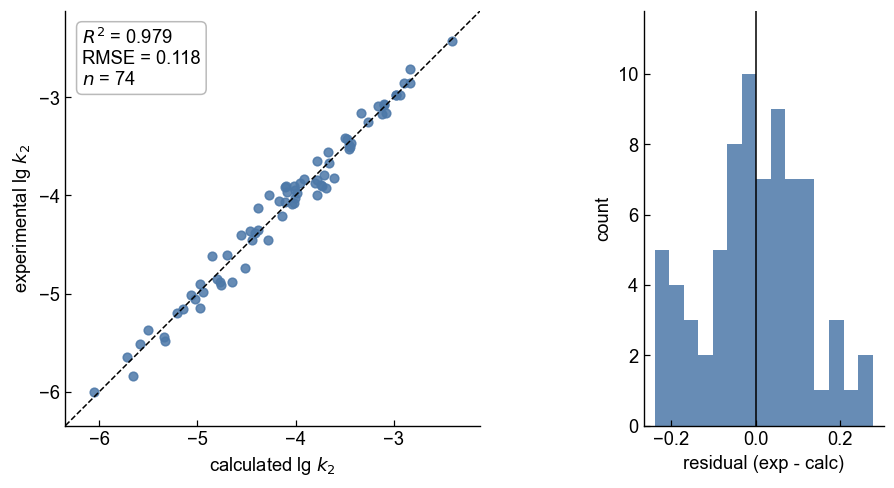

Largest residuals:


,nucleophile,electrophile,lgk,lgk_calc,residual
7,3-cyanopyridine,P5,-3.990625,-4.266569,0.275943
67,hydroxylamine,P9,-4.125936,-4.382800,0.256864
3,"3,4-lutidine",P5,-3.926494,-3.688621,-0.237874
62,4-ethylpyridine,P9,-4.880327,-4.648650,-0.231677
18,"3,4-lutidine",P6,-4.619726,-4.849951,0.230225
63,3-methoxypyridine,P9,-4.737899,-4.515992,-0.221907
51,3-cyanopyridine,P8,-3.993483,-3.784557,-0.208926
41,imidazole,P7,-3.818482,-3.610699,-0.207783
72,imidazole,P9,-3.898697,-4.095811,0.197114
5,3-methoxypyridine,P5,-3.913375,-4.105137,0.191762


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 4.6), gridspec_kw=dict(width_ratios=[3.2, 1]))
parity_plot(fitted, ax[0])
counts, _, _ = ax[1].hist(fitted["residual"], bins=15, color="#4C78A8", alpha=0.85)
ax[1].axvline(0, color="k", lw=1)
ax[1].set_ylim(0, max(counts) * 1.18 if len(counts) else 1)
ax[1].set_xlabel("residual (exp - calc)"); ax[1].set_ylabel("count")
_despine(ax[1])
plt.tight_layout(); plt.show()

print("Largest residuals:")
display(fitted.assign(abs_res=fitted["residual"].abs()).sort_values("abs_res", ascending=False)
        [["nucleophile", "electrophile", "lgk", "lgk_calc", "residual"]].head(10))


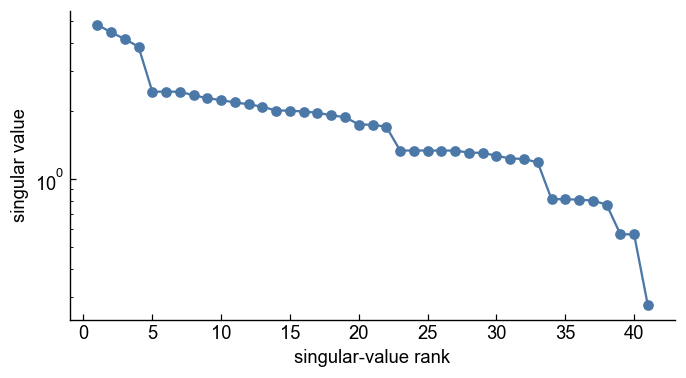

condition number ~ 17.4


In [9]:
# Numerical identifiability — singular values of the Jacobian
_, _, _, res = fit_lfer(core)
sv = np.linalg.svd(res.jac, compute_uv=False)
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.semilogy(np.arange(1, len(sv) + 1), sv, "o-", color="#4C78A8")
ax.set_xlabel("singular-value rank"); ax.set_ylabel("singular value")
_despine(ax)
plt.tight_layout(); plt.show()
print(f"condition number ~ {sv[0]/sv[-1]:.1f}")


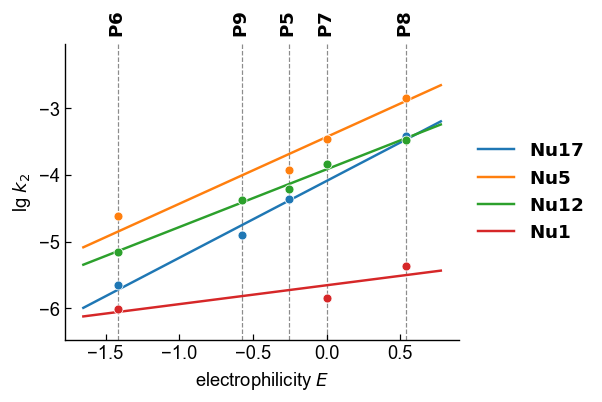

In [10]:
plot_lgk_vs_E(core, params, CONFIG.LGK_VS_E_NUCLEOPHILES)
plt.tight_layout(rect=[0, 0, 1, 0.80]); plt.show()


## 5. Bayesian bootstrap uncertainty

**Rubin's Bayesian bootstrap**: each observation gets a weight from $\mathrm{Dirichlet}(1,\dots,1)$
(mean-1 rescaled) and the LFER is refit by weighted least squares, repeated `N_BOOT` times. Unlike the
classical resampling bootstrap, every observation keeps positive weight in every replicate, so no
species ever drops out. We report **median and 2.5/97.5 %
quantiles** (robust to the occasional large $s_\mathrm{N,P}\!\cdot\!E_\mathrm{P}$ draw).

The uncertainty and prediction heat maps below cover the **core dataset only**: rows and columns are the
species that received fitted parameters. Reactions that were measured but excluded from the core are
marked with **open circles**, so it is clear which studied systems the map does not use; solid crosses
mark reactions used in the fit. Species without fitted parameters cannot appear as rows.


In [11]:
def bayesian_bootstrap(data, cfg=CONFIG, n_boot=None, seed=None,
                       anchor_nuc=None, anchor_elec=None):
    n_boot = n_boot or cfg.N_BOOT
    seed = cfg.BOOT_SEED if seed is None else seed
    d = data.reset_index(drop=True); n = len(d); rng = np.random.default_rng(seed)
    draws, fails = [], 0
    for b in range(n_boot):
        w = rng.dirichlet(np.ones(n)) * n
        try:
            p, _, m, _ = fit_lfer(d, cfg, weights=w, anchor_nuc=anchor_nuc, anchor_elec=anchor_elec)
            if not m["success"]:
                fails += 1; continue
            p["bootstrap_id"] = b; draws.append(p)
        except Exception:
            fails += 1
    boot = pd.concat(draws, ignore_index=True)
    summ = (boot.groupby(["type", "species", "parameter"])["estimate"]
            .agg(median="median", lo95=lambda x: np.quantile(x, .025), hi95=lambda x: np.quantile(x, .975),
                 sd="std", n_boot="count").reset_index())
    summ["ci_width"] = summ["hi95"] - summ["lo95"]
    return boot, summ, dict(requested=n_boot, successful=boot["bootstrap_id"].nunique(), failed=fails)

boot, boot_summary, boot_diag = bayesian_bootstrap(core)
print(boot_diag)
boot_summary = boot_summary.merge(params.rename(columns={"estimate": "point"}),
                                  on=["type", "species", "parameter"], how="left")
display(boot_summary.sort_values(["type", "parameter", "species"]).round(3))


{'requested': 600, 'successful': 600, 'failed': 0}


,type,species,parameter,median,lo95,hi95,sd,n_boot,ci_width,point
0,electrophile,P5,E,-0.267,-0.358,-0.174,0.047,600,0.184,-0.255
1,electrophile,P6,E,-1.429,-1.835,-1.259,0.146,600,0.576,-1.416
2,electrophile,P7,E,0.000,0.000,0.000,0.000,600,0.000,0.000
3,electrophile,P8,E,0.543,0.470,0.669,0.049,600,0.200,0.540
4,electrophile,P9,E,-0.599,-0.756,-0.471,0.073,600,0.284,-0.577
5,nucleophile,"2,2,2-trifluoroethylamine",N,-4.961,-5.003,-4.880,0.034,600,0.123,-4.965
7,nucleophile,"3,4-lutidine",N,-3.444,-3.575,-3.270,0.077,600,0.305,-3.434
9,nucleophile,3-cyanopyridine,N,-4.082,-4.259,-3.763,0.132,600,0.495,-4.112
11,nucleophile,3-methoxypyridine,N,-3.782,-3.896,-3.644,0.066,600,0.252,-3.781
13,nucleophile,3-methylpyridine,N,-3.662,-3.720,-3.598,0.030,600,0.123,-3.661


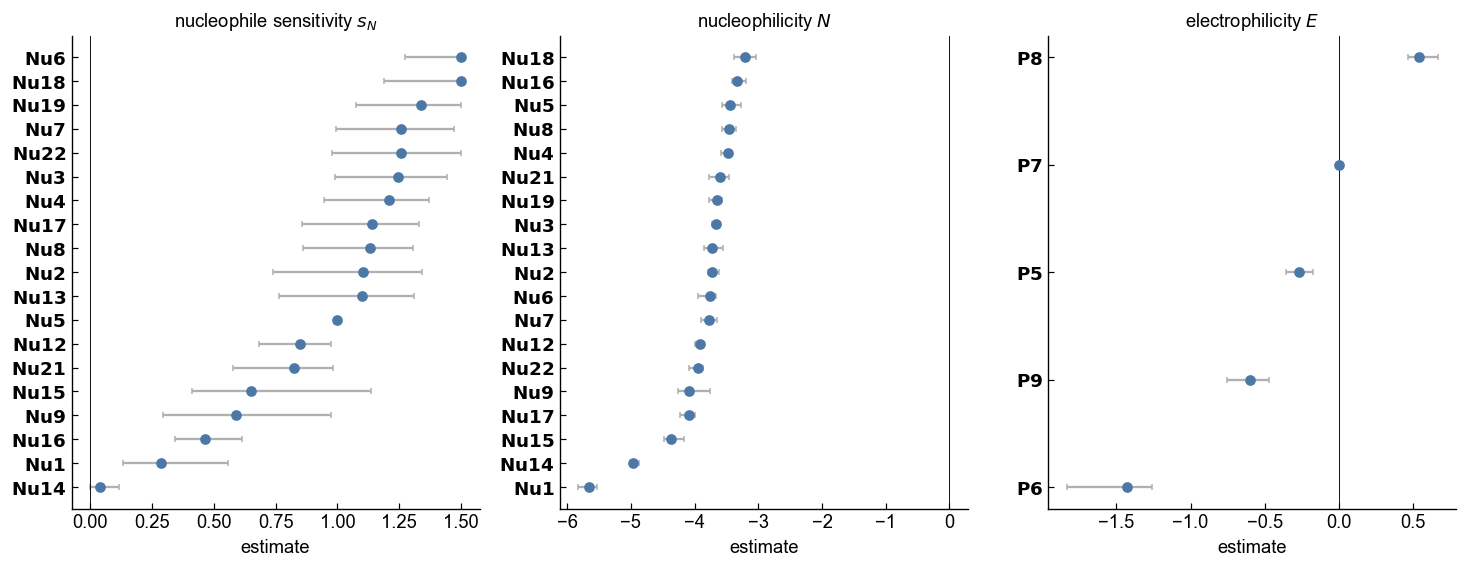

In [12]:
# Bayesian-bootstrap parameter interval plots, separated by parameter family.
def parameter_interval_panel(summary, parameter, ax, title):
    ps = summary[summary["parameter"] == parameter].copy()
    ps["id_label"] = [species_id(sp, role) for sp, role in zip(ps["species"], ps["type"])]
    ps = ps.sort_values("median").reset_index(drop=True)
    ypos = np.arange(len(ps))
    ax.errorbar(ps["median"], ypos, xerr=[ps["median"] - ps["lo95"], ps["hi95"] - ps["median"]],
                fmt="o", color="#4C78A8", ecolor="#B0B0B0", capsize=2)
    ax.set_yticks(ypos); ax.set_yticklabels(ps["id_label"])
    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel("estimate")
    _despine(ax)
    ax.set_title(title)
    return ps

fig, axes = plt.subplots(1, 3, figsize=(13.5, max(4.5, 0.28 * boot_summary.query("parameter in ['N', 's']").species.nunique())))
parameter_interval_panel(boot_summary, "s", axes[0], "nucleophile sensitivity $s_N$")
parameter_interval_panel(boot_summary, "N", axes[1], "nucleophilicity $N$")
parameter_interval_panel(boot_summary, "E", axes[2], "electrophilicity $E$")
plt.tight_layout(); plt.show()


In [13]:
# Prediction helpers + global model dispersion
model_bias = fitted["residual"].mean()
model_dispersion = np.sqrt(np.mean((fitted["residual"] - model_bias)**2))
print(f"model bias={model_bias:+.3f}  dispersion={model_dispersion:.3f}  (95% ~ {1.96*model_dispersion:.2f} lg units)")

def boot_prediction(boot_df, nucleophile, electrophile):
    vals = []
    for _, g in boot_df.groupby("bootstrap_id"):
        p = _param_lookup(g)
        try:
            vals.append(predict_lgk(p, nucleophile, electrophile))
        except KeyError:
            pass
    return np.asarray(vals, float)


model bias=-0.000  dispersion=0.118  (95% ~ 0.23 lg units)


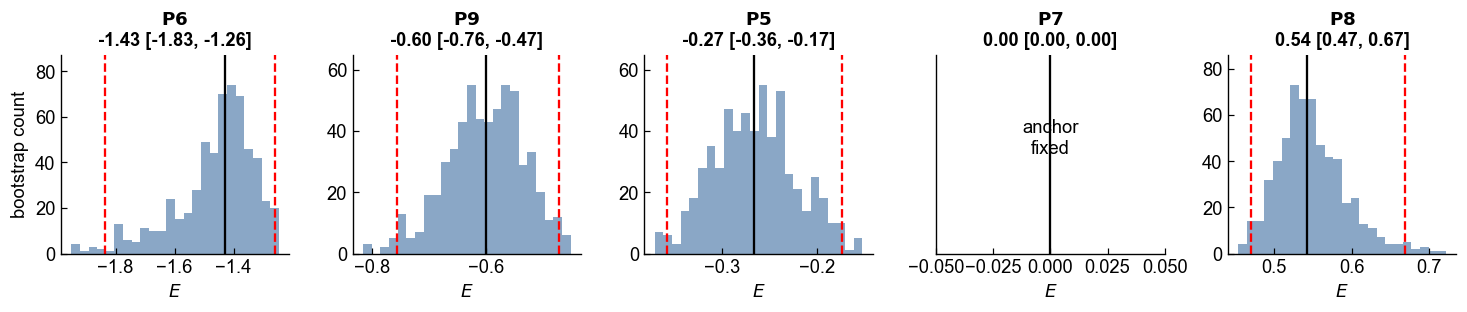

In [14]:
# Bootstrap distributions of the electrophilicity parameters E
# P7 is the E=0 anchor, so its bootstrap distribution is intentionally degenerate.
elecs = sorted(core.electrophile.unique(), key=lambda e: _param_lookup(params)[("electrophile", e, "E")])
fig, axes = plt.subplots(1, len(elecs), figsize=(2.7*len(elecs), 3.0), sharey=False)
axes = np.atleast_1d(axes)
for ax, e in zip(axes, elecs):
    x = boot.query("type=='electrophile' and species==@e and parameter=='E'")["estimate"].to_numpy()
    x = x[np.isfinite(x)]
    lo, hi = np.quantile(x, [.025, .975])
    med = np.median(x)
    if np.nanstd(x) <= 1e-12:
        ax.axvline(med, color="k", lw=1.5)
        ax.text(0.5, 0.58, "anchor\nfixed", transform=ax.transAxes, ha="center", va="center")
        ax.set_xlim(med - 0.05, med + 0.05)
        ax.set_ylim(0, 1)
        ax.set_yticks([])
    else:
        xt = x[(x > np.quantile(x, .01)) & (x < np.quantile(x, .99))]
        counts, _, _ = ax.hist(xt, bins=24, density=False, alpha=0.65, color="#4C78A8")
        ax.axvline(med, color="k"); ax.axvline(lo, color="r", ls="--"); ax.axvline(hi, color="r", ls="--")
        ax.set_ylim(0, max(counts) * 1.18 if len(counts) else 1)
    ax.set_title(f"{electrophile_id(e)}\n{med:.2f} [{lo:.2f}, {hi:.2f}]", fontweight="bold")
    ax.set_xlabel("$E$")
    _despine(ax)
axes[0].set_ylabel("bootstrap count")
plt.tight_layout(); plt.show()


studied-but-excluded reactions marked with open circles: 10


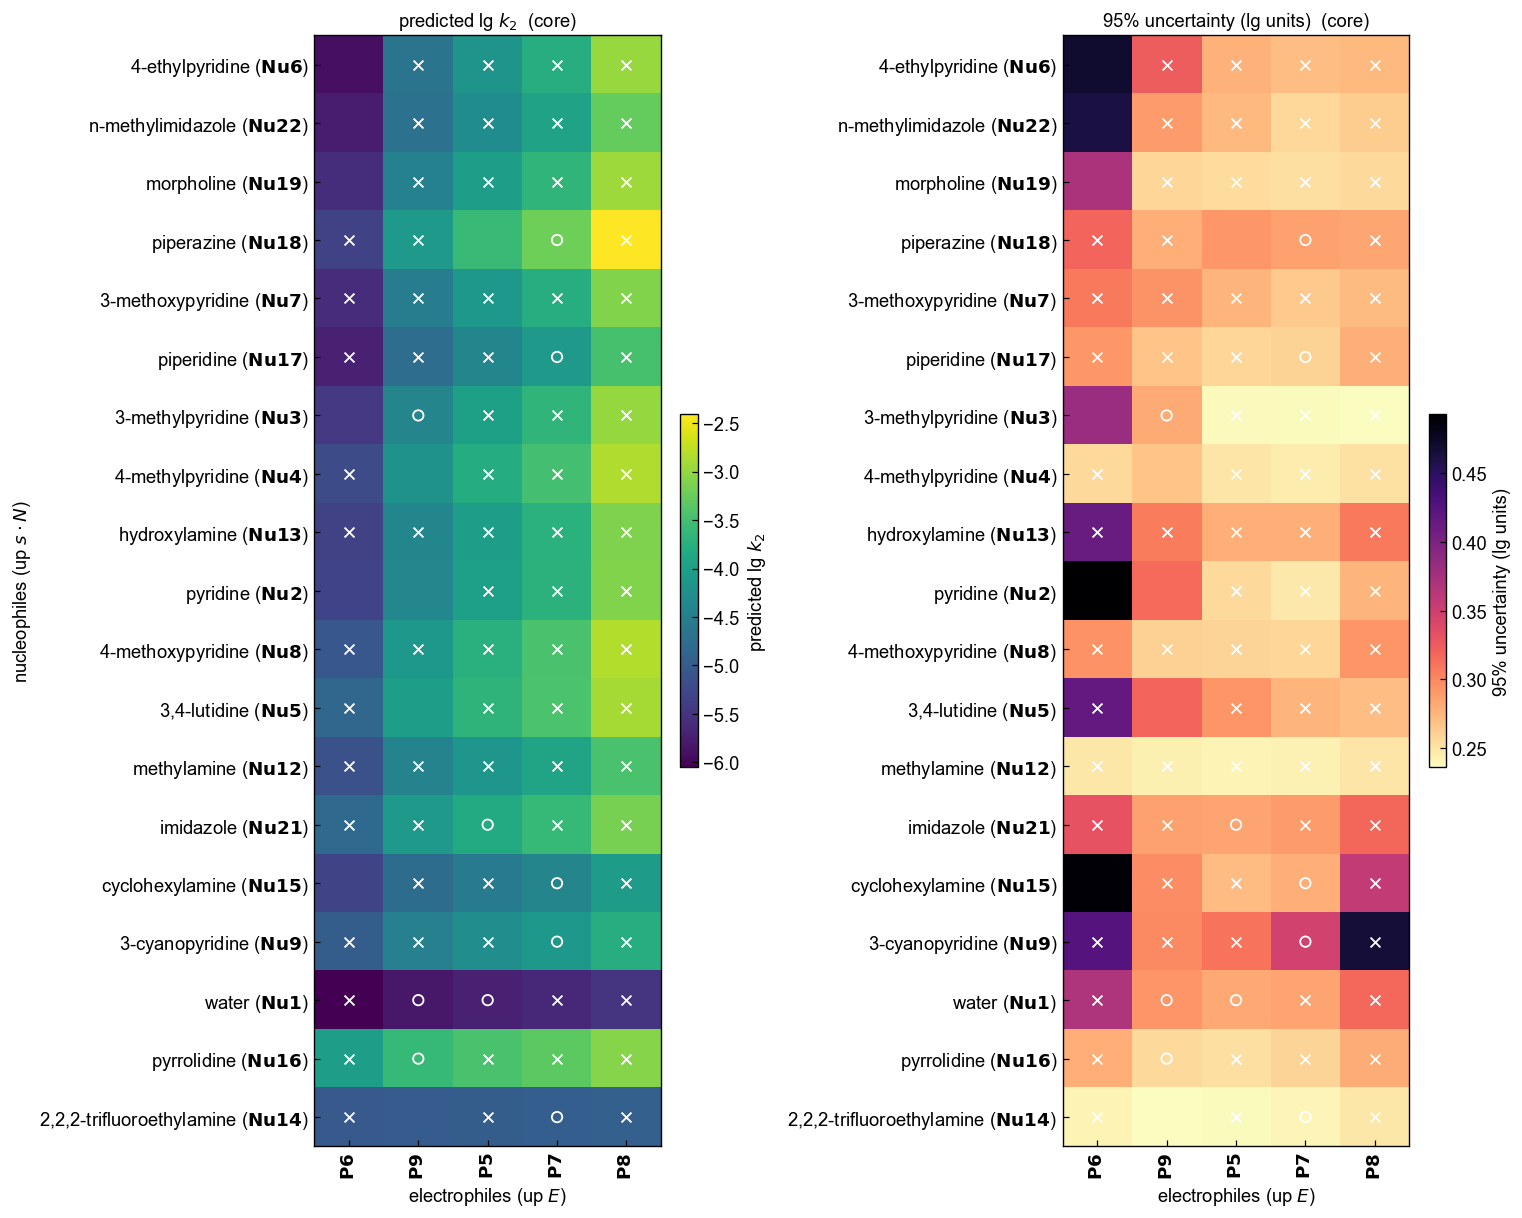

In [15]:
# Prediction-uncertainty & predicted-lg k heat maps (core dataset)
def sort_orders(params):
    p = _param_lookup(params)
    elecs = sorted({s for (t, s, q) in p if t == "electrophile"})
    nucs  = sorted({s for (t, s, q) in p if t == "nucleophile"})
    E_order = sorted(elecs, key=lambda e: p[("electrophile", e, "E")])
    N_order = sorted(nucs, key=lambda n: p[("nucleophile", n, "s")] * p[("nucleophile", n, "N")])
    return N_order, E_order

def heatmaps(params, boot_df, observed_used, observed_excluded=frozenset(),
             disp=None, title_suffix="", uncertainty_mask_threshold=5.0):
    disp = model_dispersion if disp is None else disp
    p = _param_lookup(params); N_order, E_order = sort_orders(params)
    K = np.full((len(N_order), len(E_order)), np.nan); U = K.copy()
    for i, n in enumerate(N_order):
        for j, e in enumerate(E_order):
            K[i, j] = predict_lgk(p, n, e)
            pd_ = boot_prediction(boot_df, n, e)
            if len(pd_) >= 5:
                U[i, j] = 1.96 * np.sqrt(disp**2 + np.nanvar(pd_, ddof=1))
    high_uncertainty = np.isfinite(U) & (U > uncertainty_mask_threshold)
    fig, axes = plt.subplots(1, 2, figsize=(1.0*len(E_order)+9, 0.46*len(N_order)+2.5))
    for ax, M, lab, cmap in [(axes[0], K, "predicted lg $k_2$", "viridis"),
                             (axes[1], U, "95% uncertainty (lg units)", "magma_r")]:
        cmap_obj = plt.get_cmap(cmap).copy()
        cmap_obj.set_bad("lightgrey")
        im = ax.imshow(np.ma.masked_where(high_uncertainty, M), aspect="auto", cmap=cmap_obj)
        fig.colorbar(im, ax=ax, label=lab, fraction=0.046)
        for i, n in enumerate(N_order):
            for j, e in enumerate(E_order):
                if (n, e) in observed_used:
                    ax.scatter(j, i, marker="x", s=42, c="white", linewidths=1.2)
                elif (n, e) in observed_excluded:
                    ax.scatter(j, i, marker="o", s=46, facecolors="none", edgecolors="white", linewidths=1.2)
        ax.set_xticks(range(len(E_order))); ax.set_xticklabels([electrophile_id(e) for e in E_order], rotation=90)
        ax.set_yticks(range(len(N_order))); ax.set_yticklabels([nucleophile_name_id(n) for n in N_order])
        for tick in ax.get_xticklabels():
            tick.set_fontweight("bold")
        ax.set_xlabel("electrophiles (up $E$)"); ax.set_title(lab + title_suffix)
    axes[0].set_ylabel(r"nucleophiles (up $s\cdot N$)")
    plt.tight_layout(); plt.show()

# used = reactions in the core fit; excluded = measured hte_kinetics reactions for core species that were pruned
core_species_nuc = set(core.nucleophile); core_species_elec = set(core.electrophile)
observed_used = set(zip(core["nucleophile"], core["electrophile"]))
studied = own[own.nucleophile.isin(core_species_nuc) & own.electrophile.isin(core_species_elec)]
observed_excluded = set(zip(studied["nucleophile"], studied["electrophile"])) - observed_used
print(f"studied-but-excluded reactions marked with open circles: {len(observed_excluded)}")
heatmaps(params, boot, observed_used, observed_excluded, title_suffix="  (core)")


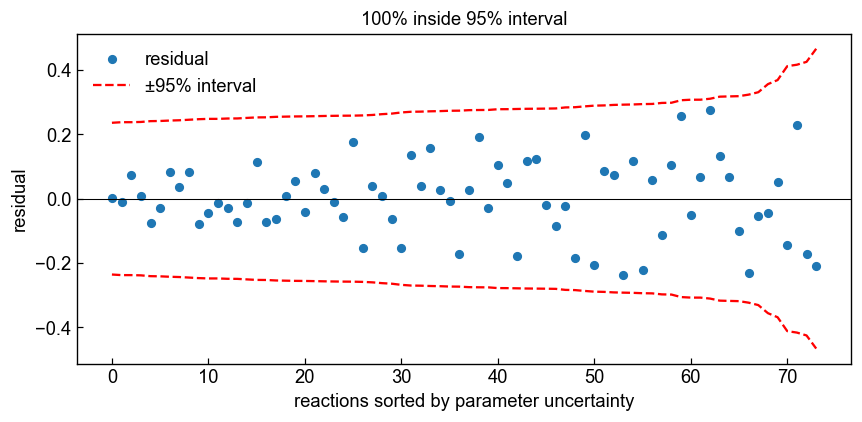

In [16]:
# Calibration: fraction of observed residuals inside the bootstrap 95% prediction interval
rows = []
for _, r in fitted.iterrows():
    pd_ = boot_prediction(boot, r["nucleophile"], r["electrophile"])
    beta = np.nanstd(pd_, ddof=1) if len(pd_) > 1 else 0.0
    U95 = 1.96 * np.sqrt(model_dispersion**2 + beta**2)
    rows.append((r["residual"], beta, U95, abs(r["residual"]) <= U95))
cal = pd.DataFrame(rows, columns=["residual", "beta", "U95", "inside"]).sort_values("beta").reset_index(drop=True)
x = np.arange(len(cal))
plt.figure(figsize=(8, 4))
plt.scatter(x, cal["residual"], s=25, label="residual")
plt.plot(x, cal["U95"], "r--", label="±95% interval"); plt.plot(x, -cal["U95"], "r--")
plt.axhline(0, color="k", lw=0.7)
plt.xlabel("reactions sorted by parameter uncertainty"); plt.ylabel("residual")
plt.title(f"{100*cal['inside'].mean():.0f}% inside 95% interval"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()


## 6. Extending the fixed scale to low-coverage `hte_kinetics` nucleophiles

The core parameters (Sections 3-5) are treated as fixed, and `hte_kinetics` nucleophiles that did not
enter the core are placed on that same scale without changing the core fit.

The default placement is a bounded fit of $\lg k_2 = N_\mathrm{P} + s_\mathrm{N,P}E_\mathrm{P}$
using the same $0 \leq s_\mathrm{N,P} \leq 1.5$ bounds. Pyridines follow a coverage-dependent rule:
with four or more electrophiles $s_\mathrm{N,P}$ is fitted freely; with exactly three, the free fit
is kept only if its $s_\mathrm{N,P}$ lies inside the core-pyridine reference interval; with fewer
than three, $s_\mathrm{N,P}$ is fixed to the core-pyridine mean and only $N_\mathrm{P}$ is
estimated. Ring-N pyridines are recognized by name, including the trivial names (lutidine, picoline,
nicotinamide, nicotinic acid).

A freely fitted $s_\mathrm{N,P}$ that runs into either bound is not identifiable from the underlying data. Such a nucleophile is rejected: it receives no parameters and is reported separately with the reason.


Core pyridine s reference: mean=1.142, interval=[0.882, 1.341], n=8
Non-core hte_kinetics nucleophiles: 4 placed (2 validated with >=3 E), 2 rejected (s at bound), 4 with insufficient coverage


,nucleophile,N,s,n_reactions,n_E,rmse,method,validated
0,n-acetylcysteine,-4.528,0.160,3,3,0.312,free s,True
1,4-cyanopyridine,-4.327,1.142,3,3,0.493,pyridine mean s,True
2,4-morpholinopyridine,-4.066,1.142,2,2,0.860,pyridine mean s,False
3,4-methoxyphenol,-3.472,0.984,2,2,0.000,free s,False


Not carried forward:


,nucleophile,s,n_reactions,n_electrophiles,reason
0,methyl thioglycolate,0.0,2,2,fitted s at lower bound (0.00)
1,4-chlorophenol,0.0,2,2,fitted s at lower bound (0.00)
2,4-methylphenol,NaN,1,1,only 1 electrophile(s)
3,n-methylpyrrolidine,NaN,1,1,only 1 electrophile(s)
4,phenol,NaN,1,1,only 1 electrophile(s)
5,thioacetic acid,NaN,1,1,only 1 electrophile(s)


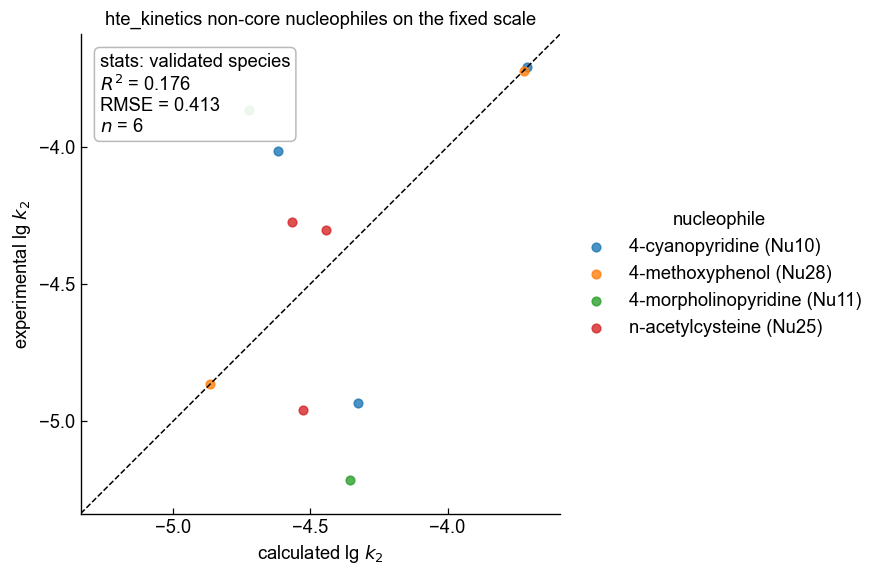

In [17]:
ref_nuc, ref_elec = param_table(params)          # from the automated hte_kinetics core
known_nuc, known_elec = set(ref_nuc.index), set(ref_elec.index)

def core_pyridine_s_reference(ref_nuc, cfg=CONFIG):
    # All core pyridines contribute, including the anchor: its s = 1 defines the scale that
    # every other s is measured against, and it is not less informative than the fitted values.
    mask = ref_nuc.index.to_series().map(lambda x: is_pyridine(x, cfg))
    vals = ref_nuc.loc[mask, "s"].dropna().to_numpy(float)
    if len(vals) == 0:
        return dict(mean=np.nan, lo=np.nan, hi=np.nan, n=0)
    if len(vals) >= 4:
        lo, hi = np.quantile(vals, [0.10, 0.90])
    else:
        sd = np.std(vals, ddof=1) if len(vals) > 1 else 0.0
        lo, hi = np.mean(vals) - 2*sd, np.mean(vals) + 2*sd
    return dict(mean=float(np.mean(vals)), lo=float(max(CONFIG.S_BOUNDS[0], lo)),
                hi=float(min(CONFIG.S_BOUNDS[1], hi)), n=int(len(vals)))

def _fit_fixed_E_group(g, cfg=CONFIG, fixed_s=None):
    x = g["E"].to_numpy(float); y = g["lgk"].to_numpy(float)
    ne = int(g["E"].nunique())
    if fixed_s is None and ne < 2:
        return None
    if fixed_s is not None:
        s = float(fixed_s)
        N = float(np.mean(y - s * x))
    else:
        def res(v):
            return v[0] * x + v[1] - y
        x0 = np.array([np.clip(1.0, *cfg.S_BOUNDS), np.mean(y)])
        opt = least_squares(res, x0, bounds=([cfg.S_BOUNDS[0], cfg.N_BOUNDS[0]],
                                            [cfg.S_BOUNDS[1], cfg.N_BOUNDS[1]]), method="trf")
        s, N = map(float, opt.x)
    calc = s * x + N
    resid = y - calc
    return dict(N=N, s=s, n_reactions=len(g), n_electrophiles=ne,
                rmse=float(np.sqrt(np.mean(resid**2))), calc=calc, resid=resid,
                s_at_lower_bound=bool(s <= cfg.S_BOUNDS[0] + 1e-4),
                s_at_upper_bound=bool(s >= cfg.S_BOUNDS[1] - 1e-4))

def _pyridine_decision(n, ne, free_fit, pyr_ref, cfg=CONFIG):
    if not is_pyridine(n, cfg):
        return dict(use_fixed_s=False, method="bounded_sN_fit",
                    status=("validated free fit (>=3 E)" if ne >= cfg.MIN_ELECTROPHILES
                            else "bounded low-coverage fit"))
    if not np.isfinite(pyr_ref["mean"]):
        return dict(use_fixed_s=False, method="bounded_sN_fit", status="pyridine reference unavailable; free bounded fit")
    if ne < cfg.MIN_ELECTROPHILES:
        return dict(use_fixed_s=True, method="fixed_core_pyridine_mean_s", status=f"pyridine <3 E; s fixed to core mean ({pyr_ref['mean']:.3f})")
    if ne >= 4:
        return dict(use_fixed_s=False, method="bounded_sN_fit", status="pyridine >=4 E; free bounded fit")
    # exactly three electrophiles: keep the free fit only if its s is consistent with core pyridines.
    if free_fit is not None and pyr_ref["lo"] <= free_fit["s"] <= pyr_ref["hi"] and not free_fit["s_at_lower_bound"] and not free_fit["s_at_upper_bound"]:
        return dict(use_fixed_s=False, method="bounded_sN_fit",
                    status=(f"pyridine 3 E; free s within core-pyridine interval "
                            f"[{pyr_ref['lo']:.3f}, {pyr_ref['hi']:.3f}]"))
    s_txt = "nan" if free_fit is None else f"{free_fit['s']:.3f}"
    return dict(use_fixed_s=True, method="fixed_core_pyridine_mean_s",
                status=(f"pyridine 3 E; free s={s_txt} outside core-pyridine interval "
                        f"[{pyr_ref['lo']:.3f}, {pyr_ref['hi']:.3f}], "
                        f"fixed to mean ({pyr_ref['mean']:.3f})"))

PLACEMENT_LABELS = {"bounded_sN_fit": "free s", "fixed_core_pyridine_mean_s": "pyridine mean s"}


def place_nucleophiles_on_fixed_E(data, E_series, known_nuc, cfg=CONFIG):
    """Place non-core nucleophiles on a fixed electrophilicity scale.

    Coverage-dependent pyridine handling as described above. A nucleophile whose freely
    fitted s runs into an imposed bound (s = 0 or s = 1.5) is not identifiable from its
    own data and is rejected rather than placed. Pyridines carrying the fixed core-mean s
    are exempt, because for them s is not fitted.
    """
    usable = data[data["electrophile"].isin(E_series.index)].copy()
    usable["E"] = usable["electrophile"].map(E_series)
    pyr_ref = core_pyridine_s_reference(ref_nuc, cfg)
    rows, fitted_rows = [], []
    for n, g in usable.groupby("nucleophile"):
        if n in known_nuc:
            continue
        g = g.copy()
        ne = int(g["E"].nunique())
        pyridine = is_pyridine(n, cfg)
        free_fit = _fit_fixed_E_group(g, cfg=cfg, fixed_s=None)
        fixed_fit = (_fit_fixed_E_group(g, cfg=cfg, fixed_s=pyr_ref["mean"])
                     if pyridine and np.isfinite(pyr_ref["mean"]) else None)
        decision = _pyridine_decision(n, ne, free_fit, pyr_ref, cfg)
        fit = fixed_fit if decision["use_fixed_s"] else free_fit
        base = dict(nucleophile=n, n_reactions=len(g), n_electrophiles=ne)

        if fit is None:
            rows.append(dict(**base, N=np.nan, s=np.nan, rmse=np.nan, placed=False, rejected=False,
                             validated=False, placement_method="not_placed",
                             status="insufficient coverage: need >=2 distinct E", reject_reason=""))
            continue

        s_is_fitted = not decision["use_fixed_s"]
        if cfg.REJECT_S_AT_BOUNDS and s_is_fitted and (fit["s_at_lower_bound"] or fit["s_at_upper_bound"]):
            side = "lower" if fit["s_at_lower_bound"] else "upper"
            reason = f"fitted s at {side} bound ({fit['s']:.2f})"
            rows.append(dict(**base, N=float(fit["N"]), s=float(fit["s"]), rmse=fit["rmse"],
                             placed=False, rejected=True, validated=False,
                             placement_method="rejected_s_at_bound",
                             status=f"rejected: {reason}; parameters not identifiable",
                             reject_reason=reason))
            continue

        validated = ne >= cfg.MIN_ELECTROPHILES
        rows.append(dict(**base, N=float(fit["N"]), s=float(fit["s"]), rmse=fit["rmse"],
                         placed=True, rejected=False, validated=validated,
                         placement_method=decision["method"], status=decision["status"],
                         reject_reason="", pyridine_s_ref_mean=pyr_ref["mean"]))
        fitted_rows.append(g.assign(lgk_calc=fit["calc"], residual=fit["resid"], n_electrophiles=ne,
                                    placement_method=decision["method"], validated=validated,
                                    status=decision["status"]))

    tab = pd.DataFrame(rows).sort_values(["placed", "N"], ascending=[False, True]).reset_index(drop=True)
    fit_df = (pd.concat(fitted_rows, ignore_index=True) if fitted_rows
              else pd.DataFrame(columns=["lgk", "lgk_calc", "residual"]))
    return tab, fit_df, pyr_ref


def placement_report(tab, title):
    "Compact two-table summary: what was placed, and what was not (with the reason)."
    acc = tab[tab["placed"]].copy()
    acc["method"] = acc["placement_method"].map(PLACEMENT_LABELS).fillna(acc["placement_method"])
    acc["n_E"] = acc["n_electrophiles"].astype(int)
    out = tab[~tab["placed"]].copy()
    print(f"{title}: {len(acc)} placed ({int(acc['validated'].sum())} validated with >=3 E), "
          f"{int(tab['rejected'].sum())} rejected (s at bound), "
          f"{int((~tab['placed'] & ~tab['rejected']).sum())} with insufficient coverage")
    display(acc[["nucleophile", "N", "s", "n_reactions", "n_E", "rmse", "method", "validated"]]
            .sort_values("N").reset_index(drop=True).round(3))
    if len(out):
        out["reason"] = np.where(out["rejected"], out["reject_reason"],
                                 "only " + out["n_electrophiles"].astype(int).astype(str) + " electrophile(s)")
        print("Not carried forward:")
        display(out[["nucleophile", "s", "n_reactions", "n_electrophiles", "reason"]]
                .reset_index(drop=True).round(3))
    return acc


core_pyridine_s_ref = core_pyridine_s_reference(ref_nuc)
print(f"Core pyridine s reference: mean={core_pyridine_s_ref['mean']:.3f}, "
      f"interval=[{core_pyridine_s_ref['lo']:.3f}, {core_pyridine_s_ref['hi']:.3f}], n={core_pyridine_s_ref['n']}")

own_extra_nuc, own_extra_fitted, _ = place_nucleophiles_on_fixed_E(own, ref_elec["E"], known_nuc)
placement_report(own_extra_nuc, "Non-core hte_kinetics nucleophiles")


if len(own_extra_fitted):
    fig, ax = plt.subplots(figsize=(7.6, 5.4))
    validated = own_extra_fitted[own_extra_fitted["validated"]]
    parity_plot(own_extra_fitted, ax, by="nucleophile",
                label_fmt=lambda n: nucleophile_name_id(n, bold=False),
                stats_fitted=validated if len(validated) else None,
                stats_label="stats: validated species" if len(validated) else None,
                legend_outside=True, legend_title="nucleophile")
    ax.set_title("hte_kinetics non-core nucleophiles on the fixed scale")
    plt.tight_layout(); plt.show()


## 7. External check against literature rate constants

No literature datum contributes to any parameter in this notebook, and literature is used as an external test. Every reaction of the high-throughput dataset for which an independently reported rate constant exists enters this check.

Two comparisons are made. The first is model-free: the two measured values for the same reaction are compared directly, which isolates the difference between the datasets without involving the LFER at all. 

The second compares the literature value with the value predicted from the LFER scale, and therefore carries the model error in addition to the difference between the datasets. The
prediction uses the core parameters together with the nucleophiles attached in Section 6, i.e. parameters derived exclusively from the measurements of this work.


Reactions of this work with a literature counterpart: 23 (25 literature rows), covering 4 phosphorylating agents and 14 nucleophiles.


,electrophile,nucleophile,lgk_hte,lgk_lit,lit_minus_hte,lgk_calc,residual,lit_source
0,P6,water,-6.001,-6.679,-0.678,-6.052,-0.627,JACS1967
1,P7,water,-5.837,-6.409,-0.572,-5.652,-0.757,J.Chem.Soc.B.1970
2,P8,water,-5.366,-5.523,-0.156,-5.500,-0.023,JACS1987
3,P8,water,-5.366,-5.469,-0.102,-5.500,0.031,J.Chem.Soc.B.1970
4,P5,water,-4.622,-4.623,-0.000,-5.724,1.101,JACS1967
5,P7,4-methylpyridine,-3.411,-3.319,0.092,-3.492,0.173,J.Chem.Soc.B.1970
6,P7,imidazole,-3.818,-3.678,0.141,-3.611,-0.067,J.Chem.Soc.B.1970
7,P7,3-methylpyridine,-3.672,-3.456,0.216,-3.661,0.205,J.Chem.Soc.B.1970
8,P8,3-methoxypyridine,-3.069,-2.836,0.233,-3.095,0.259,JACS1984
9,P7,n-methylimidazole,-3.876,-3.602,0.274,-3.955,0.353,J.Chem.Soc.B.1970


Difference between the two measurements of the same reaction (model-free):


,n,mean,median,rmse,sd,ci95_lo,ci95_hi,p_mean_zero,rmse_after_offset
0,25,0.416,0.34,0.686,0.556,0.198,0.634,0.001,0.545


Deviation of the literature value from the fixed scale of this work:


,n,mean,median,rmse,sd,ci95_lo,ci95_hi,p_mean_zero,rmse_after_offset
0,25,0.482,0.394,0.758,0.597,0.248,0.716,0.0,0.585


Model-based deviation resolved by phosphorylating agent:


,electrophile,n,mean,median,rmse,sd,ci95_lo,ci95_hi,p_mean_zero,rmse_after_offset
0,P5,1,1.101,1.101,1.101,NaN,NaN,NaN,NaN,0.000
1,P6,1,-0.627,-0.627,0.627,NaN,NaN,NaN,NaN,0.000
2,P7,9,0.385,0.218,0.740,0.671,-0.053,0.823,0.123,0.632
3,P8,14,0.579,0.428,0.748,0.491,0.322,0.836,0.001,0.473


Model-based deviation resolved by literature source:


,lit_source,n,mean,median,rmse,sd,ci95_lo,ci95_hi,p_mean_zero,rmse_after_offset
0,J.Chem.Soc.B.1970,13,0.461,0.353,0.772,0.645,0.110,0.811,0.024,0.620
1,JACS1967,2,0.237,0.237,0.896,1.222,-1.457,1.931,0.829,0.864
2,JACS1984,9,0.622,0.455,0.746,0.436,0.337,0.907,0.003,0.411
3,JACS1987,1,-0.023,-0.023,0.023,NaN,NaN,NaN,NaN,0.000


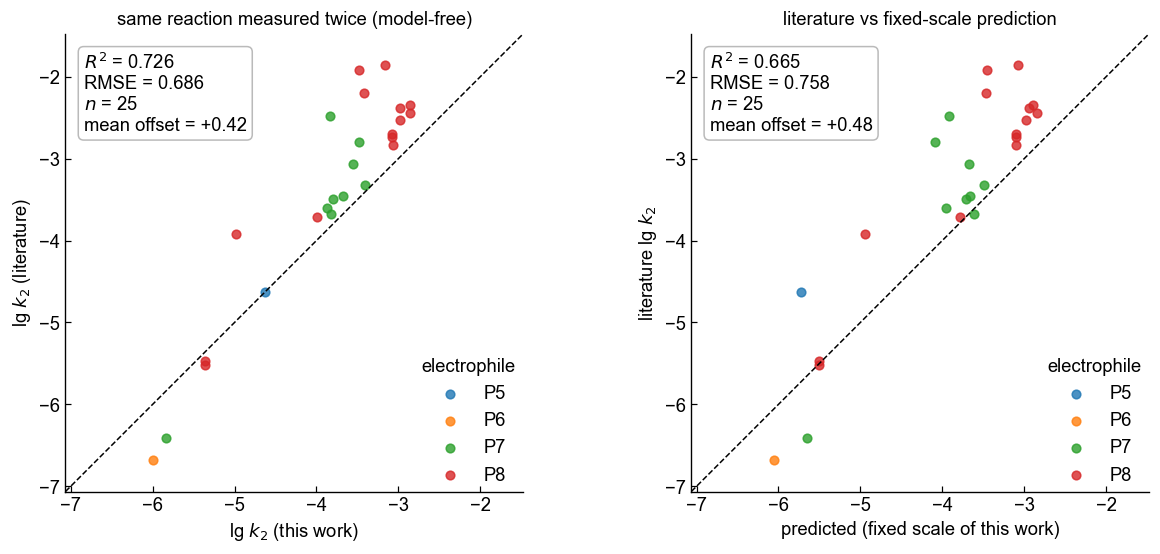

In [18]:
# The fixed scale of this work: the core fit plus the Section 6 attachments.
fixed_scale_params = pd.concat([
    params,
    pd.DataFrame([dict(type="nucleophile", species=r["nucleophile"], parameter=p, estimate=r[p])
                  for _, r in own_extra_nuc[own_extra_nuc["placed"]].iterrows()
                  for p in ("N", "s")]),
], ignore_index=True, sort=False).drop_duplicates(["type", "species", "parameter"], keep="first")
_pl_fixed = _param_lookup(fixed_scale_params)


def _predict_or_nan(n, e):
    try:
        return predict_lgk(_pl_fixed, n, e)
    except KeyError:
        return np.nan


# Pair every HTE reaction with its literature counterpart. Replicate HTE rows for one pair are
# averaged in lg space; every individual literature row is kept.
_own_lgk = (own_raw.groupby(["nucleophile", "electrophile"], as_index=False)
            .agg(lgk_hte=("lgk", "mean"), n_hte=("lgk", "size")))
literature_external_check = (lit.rename(columns={"lgk": "lgk_lit"})
                             .merge(_own_lgk, on=["nucleophile", "electrophile"], how="inner"))
literature_external_check["lit_minus_hte"] = (literature_external_check["lgk_lit"]
                                              - literature_external_check["lgk_hte"])
literature_external_check["lgk_calc"] = [_predict_or_nan(n, e) for n, e
                                         in zip(literature_external_check.nucleophile,
                                                literature_external_check.electrophile)]
# `lgk` / `residual` are the columns the shared helpers expect.
literature_external_check["lgk"] = literature_external_check["lgk_lit"]
literature_external_check["residual"] = (literature_external_check["lgk_lit"]
                                         - literature_external_check["lgk_calc"])

n_pairs = literature_external_check.groupby(["nucleophile", "electrophile"]).ngroups
print(f"Reactions of this work with a literature counterpart: {n_pairs} "
      f"({len(literature_external_check)} literature rows), covering "
      f"{literature_external_check.electrophile.nunique()} phosphorylating agents and "
      f"{literature_external_check.nucleophile.nunique()} nucleophiles.")
display(literature_external_check[["electrophile", "nucleophile", "lgk_hte", "lgk_lit",
                                   "lit_minus_hte", "lgk_calc", "residual", "lit_source"]]
        .sort_values("lit_minus_hte").round(3).reset_index(drop=True))


def residual_shift_summary(df, group_cols=None, residual_col="residual"):
    "Mean/median shift with a 95% interval and a one-sample t-test against zero."
    group_cols = group_cols or []
    rows = []
    groups = [((), df)] if not group_cols else df.groupby(group_cols, dropna=False)
    for key, sub in groups:
        r = sub[residual_col].dropna().to_numpy(float)
        if len(r) == 0:
            continue
        key = key if isinstance(key, tuple) else (key,)
        mean = float(np.mean(r))
        sd = float(np.std(r, ddof=1)) if len(r) > 1 else np.nan
        se = sd / np.sqrt(len(r)) if len(r) > 1 else np.nan
        row = {c: v for c, v in zip(group_cols, key)}
        row.update(dict(n=len(r), mean=mean, median=float(np.median(r)),
                        rmse=float(np.sqrt(np.mean(r**2))), sd=sd,
                        ci95_lo=mean - 1.96*se if np.isfinite(se) else np.nan,
                        ci95_hi=mean + 1.96*se if np.isfinite(se) else np.nan,
                        p_mean_zero=float(ttest_1samp(r, 0.0).pvalue) if len(r) > 1 else np.nan,
                        rmse_after_offset=float(np.sqrt(np.mean((r - mean)**2)))))
        rows.append(row)
    return pd.DataFrame(rows)


print("Difference between the two measurements of the same reaction (model-free):")
direct_shift_summary = residual_shift_summary(literature_external_check, residual_col="lit_minus_hte")
display(direct_shift_summary.round(3))
print("Deviation of the literature value from the fixed scale of this work:")
model_shift_summary = residual_shift_summary(literature_external_check)
display(model_shift_summary.round(3))
print("Model-based deviation resolved by phosphorylating agent:")
display(residual_shift_summary(literature_external_check, ["electrophile"]).round(3))
print("Model-based deviation resolved by literature source:")
display(residual_shift_summary(literature_external_check, ["lit_source"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11.6, 5.2))

# Left: the two measurements of the same reaction compared directly. Casting the value of this work
# as the "calculated" axis lets the shared parity helper report exactly the same statistics as the
# model-based panel on the right, so the two are directly comparable.
direct_check = literature_external_check.assign(
    lgk_calc=literature_external_check["lgk_hte"],
    residual=literature_external_check["lit_minus_hte"])
parity_plot(direct_check, ax[0], by="electrophile",
            label_fmt=lambda e: electrophile_id(e, bold=False), legend_title="electrophile",
            extra_lines=[f"mean offset = {direct_check['residual'].mean():+.2f}"])
ax[0].set_xlabel("lg $k_2$ (this work)"); ax[0].set_ylabel("lg $k_2$ (literature)")
ax[0].set_title("same reaction measured twice (model-free)")

# Right: literature value against the value predicted from the fixed scale of this work.
model_check = literature_external_check.dropna(subset=["lgk_calc"])
parity_plot(model_check, ax[1], by="electrophile",
            label_fmt=lambda e: electrophile_id(e, bold=False), legend_title="electrophile",
            extra_lines=[f"mean offset = {model_check['residual'].mean():+.2f}"])
ax[1].set_xlabel("predicted (fixed scale of this work)"); ax[1].set_ylabel("literature lg $k_2$")
ax[1].set_title("literature vs fixed-scale prediction")
plt.tight_layout(); plt.show()


## 8. Export results and metadata

Two Excel workbooks are written, to `CONFIG.OUTPUT_FILE` and `CONFIG.METADATA_FILE`:

* the **results** workbook — the parameter tables for the electrophiles and nucleophiles of this work
  including their confidence intervals, the fitted core reactions, a summary of the fit statistics,
  and the species that were rejected or could not be placed together with the reason;
* the **metadata** workbook — both input datasets, the fitted core, the core bootstrap summary, the
  complete parameter table, and the external literature check.


In [19]:
def nuc_param_frame(summ, provenance=""):
    med = summ.pivot_table(index="species", columns=["type", "parameter"], values="median")
    lo = summ.pivot_table(index="species", columns=["type", "parameter"], values="lo95")
    hi = summ.pivot_table(index="species", columns=["type", "parameter"], values="hi95")
    out = []
    for sp in summ.query("type=='nucleophile'").species.unique():
        out.append({"species": sp, "role": "nucleophile", "provenance": provenance,
                    "N": med.get(("nucleophile", "N"), {}).get(sp),
                    "N_lo95": lo.get(("nucleophile", "N"), {}).get(sp),
                    "N_hi95": hi.get(("nucleophile", "N"), {}).get(sp),
                    "s": med.get(("nucleophile", "s"), {}).get(sp),
                    "s_lo95": lo.get(("nucleophile", "s"), {}).get(sp),
                    "s_hi95": hi.get(("nucleophile", "s"), {}).get(sp)})
    for sp in summ.query("type=='electrophile'").species.unique():
        out.append({"species": sp, "role": "electrophile", "provenance": provenance,
                    "E": med.get(("electrophile", "E"), {}).get(sp),
                    "E_lo95": lo.get(("electrophile", "E"), {}).get(sp),
                    "E_hi95": hi.get(("electrophile", "E"), {}).get(sp)})
    return pd.DataFrame(out)


core_params_final = nuc_param_frame(boot_summary, "hte_kinetics_core")
extended_params_final = pd.DataFrame([
    dict(species=r["nucleophile"], role="nucleophile", provenance="hte_kinetics_extended",
         N=r["N"], s=r["s"], n=r["n_reactions"], rmse=r.get("rmse", np.nan),
         validated=r["validated"], placement_method=r["placement_method"], status=r["status"])
    for _, r in own_extra_nuc[own_extra_nuc["placed"]].iterrows()])

parameter_table = pd.concat([core_params_final, extended_params_final], ignore_index=True, sort=False)

# Export convention: phosphorylating agents are identified by their P number only;
# nucleophiles keep their name together with their Nu number.
def _eid(name):
    return ELECTROPHILE_ID_MAP.get(name, name)

def _nid(name):
    return NUCLEOPHILE_ID_MAP.get(name, name)

def ids_only_electrophiles(df):
    "Replace electrophile name columns by the ID; add a missing nucleophile ID column."
    out = df.copy()
    if "electrophile" in out.columns:
        if "electrophile_id" not in out.columns:
            out.insert(out.columns.get_loc("electrophile"), "electrophile_id",
                       out["electrophile"].map(_eid))
        out = out.drop(columns=["electrophile"])
    if "raw_electrophile_name" in out.columns:
        out = out.drop(columns=["raw_electrophile_name"])
    if "nucleophile" in out.columns and "nucleophile_id" not in out.columns:
        out.insert(out.columns.get_loc("nucleophile") + 1, "nucleophile_id",
                   out["nucleophile"].map(_nid))
    return out

def ids_for_species(df):
    "Parameter-style frames: electrophile species -> ID; species_id column for every row."
    out = df.copy()
    role_col = "role" if "role" in out.columns else "type"
    is_e = (out[role_col] == "electrophile").to_numpy()
    out.insert(out.columns.get_loc("species") + 1, "species_id",
               np.where(is_e, out["species"].map(_eid), out["species"].map(_nid)))
    out.loc[is_e, "species"] = out.loc[is_e, "species"].map(_eid)
    return out


electrophile_parameters = parameter_table[parameter_table["role"] == "electrophile"].copy()
electrophile_parameters["species"] = electrophile_parameters["species"].map(_eid)
electrophile_parameters = electrophile_parameters.rename(columns={"species": "P_ID"})
nucleophile_parameters = parameter_table[parameter_table["role"] == "nucleophile"].copy()
nucleophile_parameters.insert(1, "Nu_ID", nucleophile_parameters["species"].map(_nid))

print("=== core scale (primary) ===")
display(core_params_final.round(3))
print("=== nucleophiles attached to the fixed scale (Section 6) ===")
display(extended_params_final.round(3))

strategy_summary = pd.DataFrame([dict(
    strategy="hte_kinetics only; E/N/s fixed",
    n_core=metrics["n"], n_core_nucleophiles=metrics["n_nuc"], n_core_electrophiles=metrics["n_elec"],
    core_r2=metrics["r2"], core_rmse=metrics["rmse"],
    n_attached_nucleophiles=int(own_extra_nuc["placed"].sum()),
    attached_rmse=float(np.sqrt(np.mean(own_extra_fitted["residual"]**2))) if len(own_extra_fitted) else np.nan,
    n_external_checks=len(literature_external_check),
    direct_offset_lit_minus_hte=direct_shift_summary["mean"].iloc[0],
    model_offset_lit_minus_calc=model_shift_summary["mean"].iloc[0],
    recommendation="scale defined by this work only; literature used as external check")])
print("=== summary ===")
display(strategy_summary.round(3))

result_readme = pd.DataFrame([
    dict(item="model", value="lg k2 = N_P + s_N,P * E_P"),
    dict(item="scale", value="hte_kinetics automated core; no literature datum enters any parameter"),
    dict(item="anchor_nucleophile", value="3,4-lutidine: s_N,P = 1; N_P fitted"),
    dict(item="anchor_electrophile", value="P7: E_P = 0"),
    dict(item="literature_use", value="external check only (Section 7)"),
    dict(item="quality_pre_filter", value="none; outliers removed by the automated core selection only"),
    dict(item="s_at_bounds", value="freely fitted s at 0 or 1.5 -> species rejected (see rejected_species)"),
    dict(item="metadata_workbook", value=CONFIG.METADATA_FILE),
])

rejected_species = (own_extra_nuc[~own_extra_nuc["placed"]]
                    [["nucleophile", "s", "n_reactions", "n_electrophiles",
                      "rejected", "reject_reason", "status"]].reset_index(drop=True))
rejected_species.insert(1, "nucleophile_id", rejected_species["nucleophile"].map(_nid))

metadata_sheets = {
    "input_hte_kinetics": ids_only_electrophiles(own_raw),
    "input_literature": ids_only_electrophiles(lit),
    "core_fit": ids_only_electrophiles(fitted),
    "params_core_bootstrap": ids_for_species(boot_summary),
    "params_all": ids_for_species(parameter_table),
    "external_literature_check": ids_only_electrophiles(literature_external_check),
}

with pd.ExcelWriter(CONFIG.OUTPUT_FILE) as xw:
    result_readme.to_excel(xw, sheet_name="README", index=False)
    electrophile_parameters.to_excel(xw, sheet_name="electrophiles", index=False)
    nucleophile_parameters.to_excel(xw, sheet_name="nucleophiles", index=False)
    ids_only_electrophiles(fitted).to_excel(xw, sheet_name="core_fit", index=False)
    strategy_summary.to_excel(xw, sheet_name="strategy_summary", index=False)
    rejected_species.to_excel(xw, sheet_name="rejected_species", index=False)

with pd.ExcelWriter(CONFIG.METADATA_FILE) as xw:
    result_readme.to_excel(xw, sheet_name="README", index=False)
    for sheet, df in metadata_sheets.items():
        df.to_excel(xw, sheet_name=sheet[:31], index=False)

print(f"Wrote results workbook:  {CONFIG.OUTPUT_FILE}  (6 sheets)")
print(f"Wrote metadata workbook: {CONFIG.METADATA_FILE}  ({len(metadata_sheets)} sheets + README)")
print(f"Species rejected / not placed: {len(rejected_species)}")


=== core scale (primary) ===


,species,role,provenance,N,N_lo95,N_hi95,s,s_lo95,s_hi95,E,E_lo95,E_hi95
0,"2,2,2-trifluoroethylamine",nucleophile,hte_kinetics_core,-4.961,-5.003,-4.880,0.039,0.000,0.118,NaN,NaN,NaN
1,"3,4-lutidine",nucleophile,hte_kinetics_core,-3.444,-3.575,-3.270,1.000,1.000,1.000,NaN,NaN,NaN
2,3-cyanopyridine,nucleophile,hte_kinetics_core,-4.082,-4.259,-3.763,0.589,0.296,0.975,NaN,NaN,NaN
3,3-methoxypyridine,nucleophile,hte_kinetics_core,-3.782,-3.896,-3.644,1.259,0.995,1.470,NaN,NaN,NaN
4,3-methylpyridine,nucleophile,hte_kinetics_core,-3.662,-3.720,-3.598,1.243,0.991,1.443,NaN,NaN,NaN
5,4-ethylpyridine,nucleophile,hte_kinetics_core,-3.756,-3.946,-3.666,1.500,1.275,1.500,NaN,NaN,NaN
6,4-methoxypyridine,nucleophile,hte_kinetics_core,-3.460,-3.577,-3.348,1.131,0.860,1.307,NaN,NaN,NaN
7,4-methylpyridine,nucleophile,hte_kinetics_core,-3.480,-3.579,-3.420,1.209,0.946,1.372,NaN,NaN,NaN
8,cyclohexylamine,nucleophile,hte_kinetics_core,-4.374,-4.474,-4.173,0.651,0.410,1.134,NaN,NaN,NaN
9,hydroxylamine,nucleophile,hte_kinetics_core,-3.720,-3.853,-3.551,1.098,0.764,1.308,NaN,NaN,NaN


=== nucleophiles attached to the fixed scale (Section 6) ===


,species,role,provenance,N,s,n,rmse,validated,placement_method,status
0,n-acetylcysteine,nucleophile,hte_kinetics_extended,-4.528,0.160,3,0.312,True,bounded_sN_fit,validated free fit (>=3 E)
1,4-cyanopyridine,nucleophile,hte_kinetics_extended,-4.327,1.142,3,0.493,True,fixed_core_pyridine_mean_s,pyridine 3 E; free s=0.679 outside core-pyridi...
2,4-morpholinopyridine,nucleophile,hte_kinetics_extended,-4.066,1.142,2,0.860,False,fixed_core_pyridine_mean_s,pyridine <3 E; s fixed to core mean (1.142)
3,4-methoxyphenol,nucleophile,hte_kinetics_extended,-3.472,0.984,2,0.000,False,bounded_sN_fit,bounded low-coverage fit


=== summary ===


,strategy,n_core,n_core_nucleophiles,n_core_electrophiles,core_r2,core_rmse,n_attached_nucleophiles,attached_rmse,n_external_checks,direct_offset_lit_minus_hte,model_offset_lit_minus_calc,recommendation
0,hte_kinetics only; E/N/s fixed,74,19,5,0.979,0.118,4,0.5,25,0.416,0.482,scale defined by this work only; literature us...


Wrote results workbook:  lfer_analysis_v1_results.xlsx  (6 sheets)
Wrote metadata workbook: lfer_analysis_v1_metadata.xlsx  (6 sheets + README)
Species rejected / not placed: 6
